### Top Rows

In [145]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

file_path = "results-filtered.xlsx"
df = pd.read_excel(file_path, sheet_name="kPEX")
# df = pd.read_excel(file_path, sheet_name="UMKP+")
versions="v0 v1 v2 v3".split()
branchings="S R P".split()

for v in versions: 
    df[f"{v}-prep"] = df[f"{v}-S-bnb"]=="prep"
    
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/1081155292.py:35: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/1081155292.py:35: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/1081155292.py:35: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To reta

In [141]:
# for v in versions: 
cols = [f"v1-{b}-mkp" for b in "S P".split()]

mask = df[cols].apply(lambda row: row[row != 1800].nunique() > 1, axis=1)
df.loc[mask, cols+["dataset", "k", "v0-S-total"]]
# mask.sum()

,v1-S-mkp,v1-P-mkp,dataset,k,v0-S-total


### Varying Ratio Threshold


=== Threshold 2 Analysis ===
v2-S-total wins: 140
v0-S-total wins: 531

Weaker side: col_a
Sorted in descending order of speedup:



,dataset,k,v2-S-total,v0-S-total,speedup_a,v2-heur,v0-heur,v2-prep,v0-prep,v2-S-total,v0-S-total,v2-R-total,v0-R-total,v2-P-total,v0-P-total
3725,tech-RL-caida,20,0.0,1800.0,83720.9,0.0,NaN,False,False,0.0,1800.0,0.0,1800.0,0.0,1800.0
608,caidaRouterLevel,20,0.0,1800.0,78602.6,0.0,NaN,False,False,0.0,1800.0,0.0,1800.0,0.0,1800.0
1905,lhr10,20,0.0,1800.0,50561.8,0.0,NaN,False,False,0.0,1800.0,0.0,1800.0,0.0,1800.0
1906,lhr10c,20,0.0,1800.0,49450.5,0.0,NaN,False,False,0.0,1800.0,0.0,1800.0,0.0,1800.0
1197,enron,20,0.1,1800.0,28169.0,0.0,NaN,False,False,0.1,1800.0,0.1,1800.0,0.1,1800.0
895,delaunay_n23,4,0.2,1800.0,9018.0,0.0,NaN,False,False,0.2,1800.0,0.2,1800.0,0.2,1800.0
2077,Maragal_7,15,0.2,1800.0,8633.1,0.0,NaN,False,False,0.2,1800.0,0.2,1800.0,0.2,1800.0
3623,Stanford,2,0.3,1800.0,6823.4,0.0,NaN,False,False,0.3,1800.0,0.3,1800.0,0.3,1800.0
251,amazon-2008,7,0.3,1800.0,5541.9,0.1,NaN,False,False,0.3,1800.0,0.3,1800.0,0.3,1800.0
4002,TSOPF_RS_b162_c4,7,0.3,1800.0,5323.9,0.0,NaN,False,False,0.3,1800.0,0.3,1800.0,0.3,1800.0


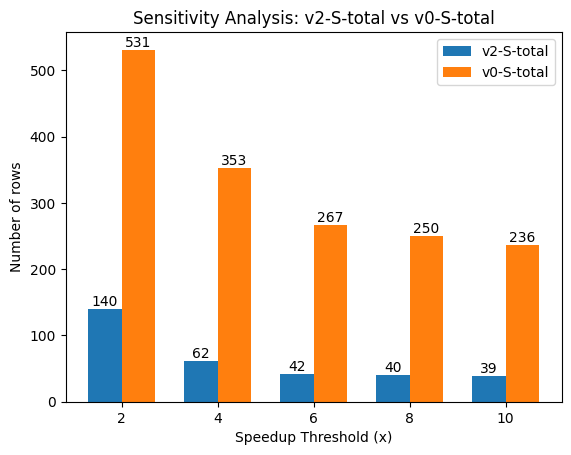

In [154]:
# =========================
# CONFIG
# =========================
col_a = "v2-S-total"
col_b = "v0-S-total"
va = col_a.split("-")[0]
vb = col_b.split("-")[0]
thresholds = [2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.01)

# =========================
# Filter
# =========================


df_filtered = df[(df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)].copy()
# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

# =========================
# Threshold = 2 analysis
# =========================
threshold_check = 2

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

# Determine weaker side
if len(a_wins) < len(b_wins):
    weaker = "A"
    weaker_df = a_wins.sort_values(by="speedup_a", ascending=False)
    speed_col = "speedup_a"
    wc=col_a.split("-")[0]
elif len(b_wins) < len(a_wins):
    weaker = "B"
    weaker_df = b_wins.sort_values(by="speedup_b", ascending=False)
    speed_col = "speedup_b"
    wc=col_b.split("-")[0]
else:
    weaker = "Tie"
    weaker_df = None
pd.set_option('display.float_format', '{:.1f}'.format)
# =========================
# Print weaker side
# =========================
print(f"\n=== Threshold {threshold_check} Analysis ===")
print(f"{col_a} wins: {len(a_wins)}")
print(f"{col_b} wins: {len(b_wins)}")

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)



if weaker == "Tie":
    print("Both sides have equal wins.")
else:
    print(f"\nWeaker side: {'col_a' if weaker == 'A' else 'col_b'}")
    print("Sorted in descending order of speedup:\n")
    max_len = 25  # choose what you like

    display(
        weaker_df.assign(
            dataset=weaker_df["dataset"].apply(
                lambda x: x[:max_len] + "..." if len(x) > max_len else x
            )
        )[["dataset", "k", col_a, col_b, speed_col, f"{va}-heur", f"{vb}-heur", f"{va}-prep", f"{vb}-prep", f"{va}-S-total", f"{vb}-S-total", f"{va}-R-total", f"{vb}-R-total",f"{va}-P-total",  f"{vb}-P-total"]]
    )
    
    # display(
    #     weaker_df.assign(
    #         dataset=weaker_df["dataset"].apply(
    #             lambda x: x[:max_len] + "..." if len(x) > max_len else x
    #         )
    #     )[["dataset", "k", col_a, col_b, speed_col]]
    # )

# =========================
# Sensitivity analysis
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

# Annotate
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of rows")
plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")

plt.legend()
plt.show()